# E-commerce Customer Segmentation and Prediction

In [92]:
import pandas as pd
import numpy as np

## 1.Load and Read Data

In [93]:
#Reading the data
df = pd.read_csv('data.csv', encoding='ISO-8859-1')

print('Shape:', df.shape)
df.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12-01-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12-01-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12-01-2010 08:26,3.39,17850.0,United Kingdom


## 2. Data Cleaning

In [94]:
#Checking data types
print('Data types:')
print(df.dtypes)

Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object


In [95]:
#Check for null values
print('\nMissing values:')
print(df.isnull().sum())


Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [96]:
#cleaning missing value rows from the dataset-CustomerID and Description 
# Drop rows with missing CustomerID or Description
df.dropna(subset=['CustomerID', 'Description'], inplace=True)
print(df.isnull().sum())

# Cast CustomerID to int
df['CustomerID'] = df['CustomerID'].astype(int)
print('Data types:')
print(df.dtypes)




InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID       int64
Country            str
dtype: object


In [97]:
# Remove invalid quantities & prices (keep negatives in raw for cancellation tracking)
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
# Parse dates (supports mixed separators/formats like "-" and "/")
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed', dayfirst=False, errors='coerce')
df = df.dropna(subset=['InvoiceDate'])

df.shape

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 3. Feature Engineering

In [98]:

# Total revenue per cutomer
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [99]:
#refrence data
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

#days since last purchase
recency = snapshot_date - df.groupby('CustomerID')['InvoiceDate'].max()

#frequency
frequency = df.groupby('CustomerID')['InvoiceNo'].nunique()

#monetary value
monetary = df.groupby('CustomerID')['TotalPrice'].sum()

In [100]:
#Average order value
average_order_value = df.groupby('CustomerID')['TotalPrice'].mean()
#Average basket size
basket_size = df.groupby('CustomerID')['Quantity'].mean()
#Number of unique products purchased
unique_products = df.groupby('CustomerID')['StockCode'].nunique()
#Number of transactions
transactions = df.groupby('CustomerID')['InvoiceNo'].nunique()
#Favourite month of purchase
favourite_month = df.groupby('CustomerID')['InvoiceDate'].agg(lambda x: x.dt.month.mode()[0] if not x.empty else np.nan)  


## 4.Exploratory Data Analysis

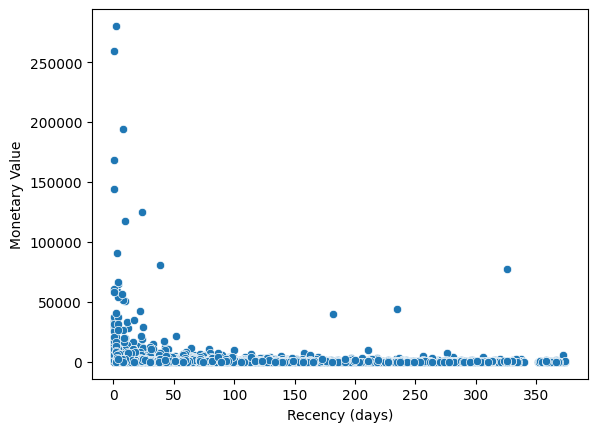

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize Recency vs Monetary Value
sns.scatterplot(x=recency.dt.days, y=monetary)
plt.xlabel('Recency (days)')
plt.ylabel('Monetary Value')
plt.show()

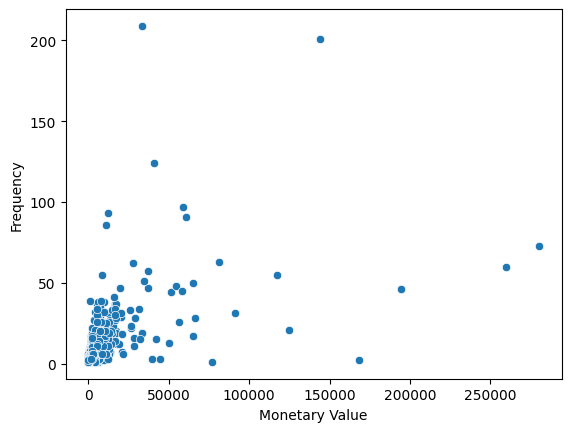

In [102]:
sns.scatterplot(x=monetary, y=frequency)
plt.xlabel('Monetary Value')
plt.ylabel('Frequency')
plt.show()

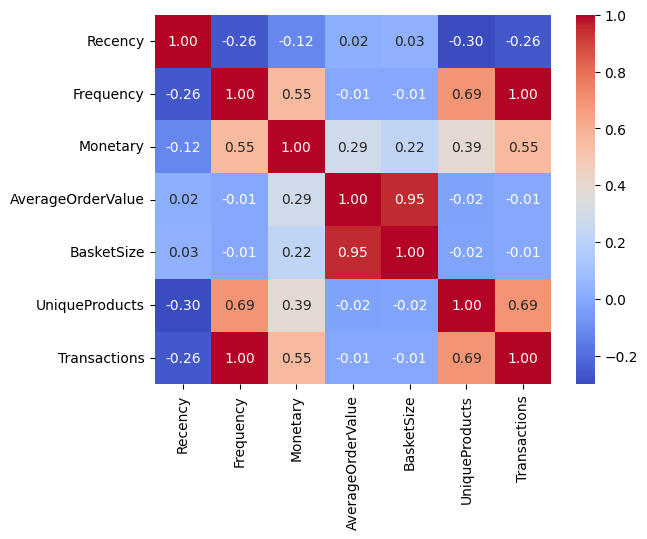

In [103]:
#correlation heatmap
customer_features = pd.DataFrame({
	'Recency': recency.dt.days,
	'Frequency': frequency,
	'Monetary': monetary,
	'AverageOrderValue': average_order_value,
	'BasketSize': basket_size,
	'UniqueProducts': unique_products,
	'Transactions': transactions
})

num_cols = ['Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'BasketSize', 'UniqueProducts', 'Transactions']
numeric_corr = customer_features[num_cols].corr()
sns.heatmap(numeric_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

## 5.Machine Learning Model

In [104]:
from sklearn.preprocessing import StandardScaler
features = customer_features[['Recency', 'Frequency', 'Monetary', 'AverageOrderValue']]
'''
features['Recency'] = features['Recency'].apply(lambda x: np.log1p(x))
features['Monetary'] = features['Monetary'].apply(lambda x: np.log1p(x))
features['AverageOrderValue'] = features['AverageOrderValue'].apply(lambda x: np.log1p(x))
features['UniqueProducts'] = features['UniqueProducts'].apply(lambda x: np.log1p(x))
features['Frequency'] = features['Frequency'].apply(lambda x: np.log1p(x))
##'''

#standardize the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
features.head()

,Recency,Frequency,Monetary,AverageOrderValue
CustomerID,,,,
12346,326,1,77183.60,77183.600000
12347,2,7,4310.00,23.681319
12348,75,4,1797.24,57.975484
12349,19,1,1757.55,24.076027
12350,310,1,334.40,19.670588


### 1.K-Mean Clustering

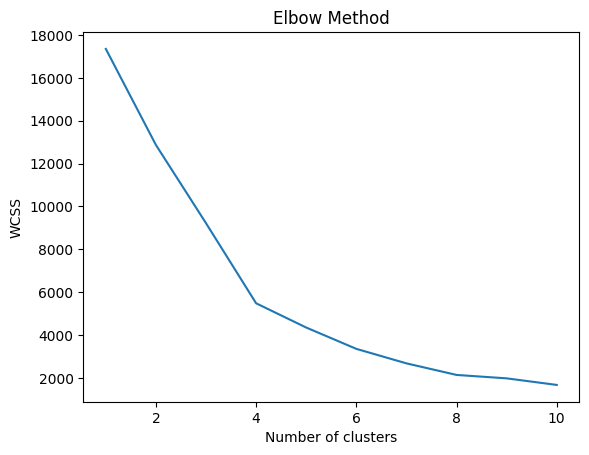

In [105]:
#ELBOW METHOD
from sklearn.cluster import KMeans
WCSS = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(scaled_features)
    WCSS.append(kmeans.inertia_)

# Plot  wcss vs number of clusters
plt.plot(range(1, 11), WCSS)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()



In [106]:
#Train the KMeans model with the optimal number of clusters (4) 
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, init='k-means++', random_state=42)
features['Kmean_Cluster']=kmeans.fit_predict(scaled_features)

In [107]:
#Model Evaluation
from sklearn.metrics import silhouette_score
silhouette_avg = silhouette_score(scaled_features, features['Kmean_Cluster'])
print(f'Silhouette Score (KMeans): {silhouette_avg}')


Silhouette Score (KMeans): 0.5911440697067313


### 2.Hierarchical Clustering

In [ ]:
#Dendrogram for Hierarchical Clustering
from scipy.cluster.hierarchy import dendrogram, linkage
linked = linkage(scaled_features, method='ward')


In [109]:
#Train model
from sklearn.cluster import AgglomerativeClustering
hc=AgglomerativeClustering(n_clusters=4)
hc.fit(scaled_features)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",4
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [110]:
#model evaluation
silhouette_avg_hc = silhouette_score(scaled_features, hc.labels_)
print(f'Silhouette Score (Hierarchical Clustering): {silhouette_avg_hc}')

Silhouette Score (Hierarchical Clustering): 0.602885382857322


### 3.DBSCAN Clustering

In [111]:
#Train DBSCAN model
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan.fit(scaled_features)


,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.5
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [112]:
# Evaluate DBSCAN model
from sklearn.metrics import silhouette_score

labels = dbscan.labels_

# Number of clusters (excluding noise label = -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print(f"Number of clusters (DBSCAN): {n_clusters}")

# Number and ratio of noise points
num_noise_points = int((labels == -1).sum())
noise_ratio = num_noise_points / len(labels)
print(f"Number of noise points (DBSCAN): {num_noise_points}")
print(f"Noise ratio: {noise_ratio:.2%}")

# Silhouette score should be computed only when at least 2 valid clusters exist.
# Also, it is better to exclude noise points for a fair cluster-quality estimate.
mask = labels != -1
valid_labels = labels[mask]
valid_data = scaled_features[mask]

if n_clusters >= 2 and len(set(valid_labels)) >= 2 and len(valid_data) > len(set(valid_labels)):
    silhouette_avg_dbscan = silhouette_score(valid_data, valid_labels)
    print(f"Silhouette Score (DBSCAN, excluding noise): {silhouette_avg_dbscan:.4f}")
else:
    print("Silhouette Score (DBSCAN): Not defined (need at least 2 non-noise clusters).")

Number of clusters (DBSCAN): 1
Number of noise points (DBSCAN): 62
Noise ratio: 1.43%
Silhouette Score (DBSCAN): Not defined (need at least 2 non-noise clusters).


##### Although DB Scan has good Silhouette score, but business usefulness matters. Two groups can be too broad for marketing strategies and customer segmentation

### Cluster Visualization

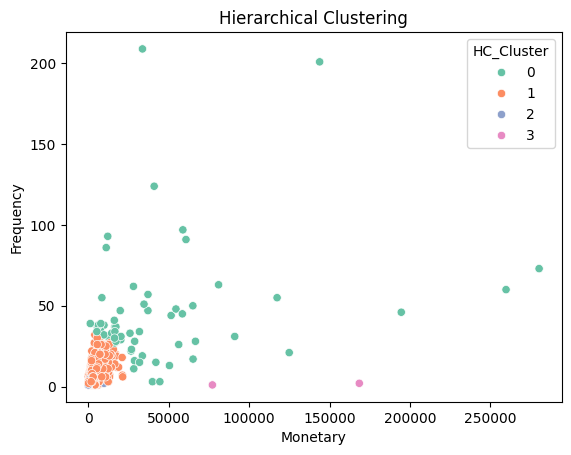

In [113]:
#Visualize the hierarchical clustering result
features['HC_Cluster'] = hc.labels_

sns.scatterplot(x='Monetary', y='Frequency', hue='HC_Cluster', data=features, palette='Set2', legend='full')
plt.title('Hierarchical Clustering')
plt.show()

#### 
0 ->    VIP Customers

1 ->    Average Customer

2 ->    low-spenders

3 ->    Bulk Order


## 6.Customer Churn Prediction

In [114]:
#Features for churn prediction
# Ensure Recency is in days (int) for churn calculation
if hasattr(features['Recency'], 'dt'):
    features['Recency'] = features['Recency'].dt.days
if pd.api.types.is_timedelta64_dtype(features['Recency']):
    features['Churn'] = (features['Recency'].dt.days > 90).astype(int)
else:
    features['Churn'] = (features['Recency'] > 90).astype(int)
features.head()

,Recency,Frequency,Monetary,AverageOrderValue,Kmean_Cluster,HC_Cluster,Churn
CustomerID,,,,,,,
12346,326,1,77183.60,77183.600000,1,3,1
12347,2,7,4310.00,23.681319,0,1,0
12348,75,4,1797.24,57.975484,0,1,0
12349,19,1,1757.55,24.076027,0,1,0
12350,310,1,334.40,19.670588,2,2,1


In [115]:

churn_count_table = pd.crosstab(features['HC_Cluster'], features['Churn'], margins=True)
churn_count_table.columns = ['No_Churn_Count', 'Churn_Count', 'Total_per_Cluster']

print("Churn Count by Hierarchical Clustering Cluster:")
print(churn_count_table)
print("\nInterpretation:")
print("- No_Churn_Count: Number of customers NOT churned")
print("- Churn_Count: Number of customers churned (Recency > 90 days)")
print("- Total_per_Cluster: Total customers in that cluster")

Churn Count by Hierarchical Clustering Cluster:
            No_Churn_Count  Churn_Count  Total_per_Cluster
HC_Cluster                                                
0                       59            3                 62
1                     2829          429               3258
2                        0         1016               1016
3                        1            1                  2
All                   2889         1449               4338

Interpretation:
- No_Churn_Count: Number of customers NOT churned
- Churn_Count: Number of customers churned (Recency > 90 days)
- Total_per_Cluster: Total customers in that cluster


In [116]:
#Model training
X=features[['Frequency', 'Monetary', 'AverageOrderValue']]
y=features['Churn']
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [117]:
#Train a Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [118]:
#MODEL EVALUATION
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
accuracy = accuracy_score(y_test, rf.predict(X_test))
print(f'Accuracy: {accuracy:.4f}')
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf.predict(X_test)))



Accuracy: 0.6694
Confusion Matrix:
[[450 111]
 [176 131]]


In [119]:
#train logistic regression

from sklearn.linear_model import LogisticRegression


log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [120]:
#Model evalution
accuracy_log_reg = accuracy_score(y_test, log_reg.predict(X_test))
print(f'Accuracy: {accuracy_log_reg:.4f}')
print("Confusion Matrix:")
print(confusion_matrix(y_test, log_reg.predict(X_test)))


Accuracy: 0.7120
Confusion Matrix:
[[456 105]
 [145 162]]


## 7.Inventory Management


In [121]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['Month'] = df['InvoiceDate'].dt.month
df['Year'] = df['InvoiceDate'].dt.year

C:\Users\hulawaka\AppData\Local\Temp\ipykernel_22796\3092764839.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette='viridis')


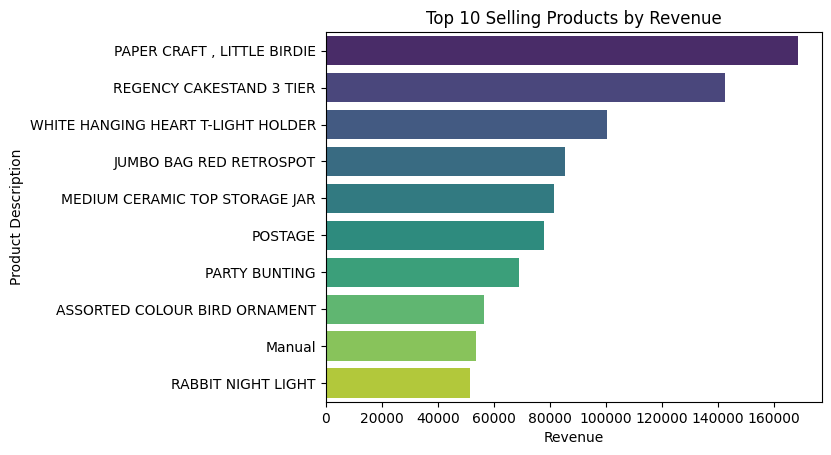

In [122]:
#Top Selling products by revenue
top_products = df.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_products.values, y=top_products.index, palette='viridis')
plt.title('Top 10 Selling Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product Description')
plt.show()